In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns

In [ ]:
fichier_data = "../data/raw/dereev_data_1_equilibre25.xlsx"

df = pd.read_excel(fichier_data)

colonne_notes = "cn_notes"
colonne_reev = 'reev_classe'
df[colonne_notes] = df[colonne_notes].astype(str)

print(f"{len(df)} notes ont été trouvées.")

369 notes ont été trouvées.


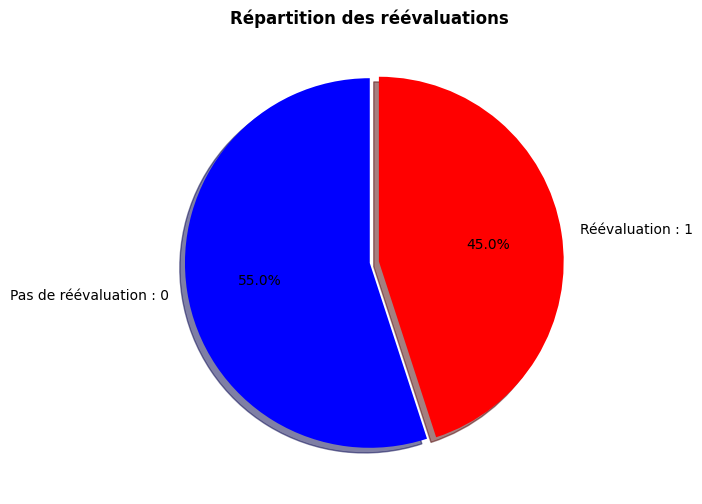

In [4]:
### PIE CHART RÉPARTITION DES CLASSES

plt.figure(figsize=(8,6))
repartition = df[colonne_reev].value_counts()
plt.pie(repartition, labels=["Pas de réévaluation : 0", "Réévaluation : 1"],
        autopct='%1.1f%%', startangle=90, explode=(0, 0.05), shadow=True, colors=["blue", 'red'])

plt.title("Répartition des réévaluations", fontweight='bold')
plt.show()

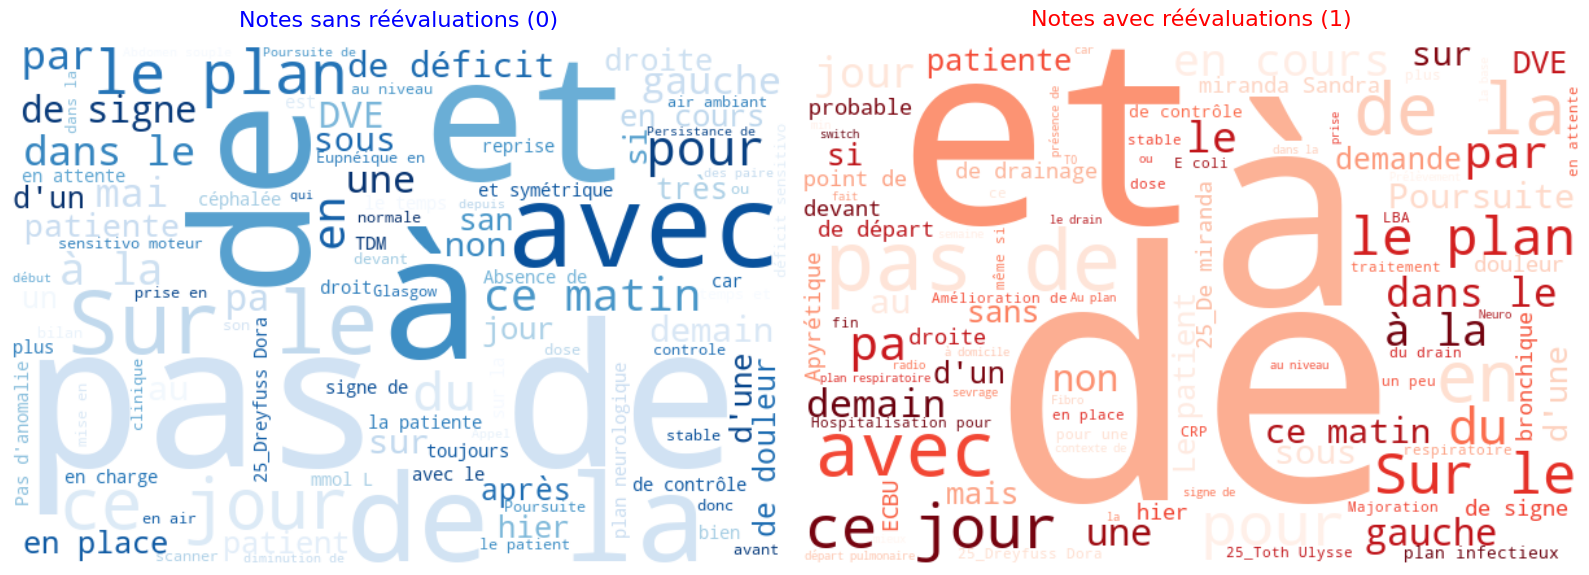

In [4]:
### WORDCLOUD 
### WORDCLOUD 

notes_0 = df.loc[df[colonne_reev] == 0, colonne_notes].dropna().astype(str)
notes_1 = df.loc[df[colonne_reev] == 1, colonne_notes].dropna().astype(str)

texte_0 = " ".join(notes_0)
texte_1 = " ".join(notes_1)

wc_0 = WordCloud(
    width=600,
    height=400,
    background_color="white",
    colormap="Blues",
    max_words=100
).generate(texte_0)

wc_1 = WordCloud(
    width=600,
    height=400,
    background_color="white",
    colormap="Reds",
    max_words=100
).generate(texte_1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(wc_0, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title("Notes sans réévaluations (0)", fontsize=16, color="blue", pad=15)

axes[1].imshow(wc_1, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Notes avec réévaluations (1)", fontsize=16, color="red", pad=15)

plt.tight_layout()
plt.show()

Moyenne      : 76.21 mots
Médiane      : 61 mots
Maximum      : 291 mots
Minimum      : 4 mots
90e Centile  : 149 mots


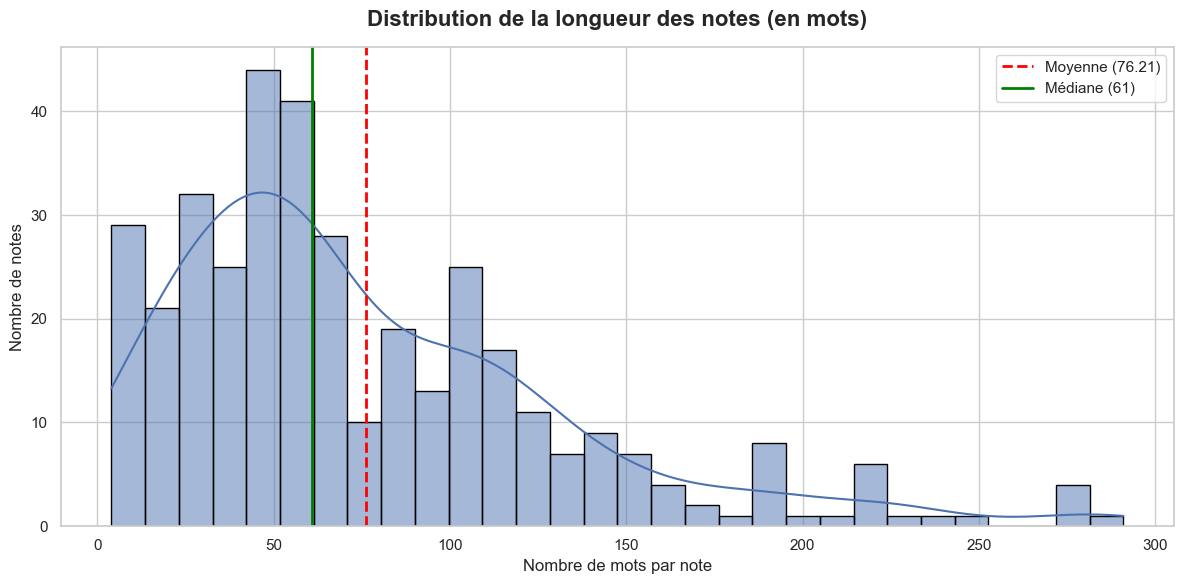

In [5]:
df = df.dropna(subset=[colonne_notes]).copy()
df[colonne_notes] = df[colonne_notes].astype(str).str.strip()
df = df[df[colonne_notes] != ""].copy()

df["longueur_mots"] = df[colonne_notes].str.split().str.len()

moyenne = df["longueur_mots"].mean()
mediane = df["longueur_mots"].median()
maximum = df["longueur_mots"].max()
minimum = df["longueur_mots"].min()
centile_90 = df["longueur_mots"].quantile(0.90)

print(f"Moyenne      : {moyenne:.2f} mots")
print(f"Médiane      : {mediane:.0f} mots")
print(f"Maximum      : {maximum} mots")
print(f"Minimum      : {minimum} mots")
print(f"90e Centile  : {centile_90:.0f} mots")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="longueur_mots",
    bins=30,
    kde=True,
    color="#4C72B0",
    edgecolor="black"
)

plt.axvline(moyenne, color="red", linestyle="--", linewidth=2, label=f"Moyenne ({moyenne:.2f})")
plt.axvline(mediane, color="green", linestyle="-", linewidth=2, label=f"Médiane ({mediane:.0f})")

plt.title("Distribution de la longueur des notes (en mots)", fontsize=16, pad=15, fontweight="bold")
plt.xlabel("Nombre de mots par note", fontsize=12)
plt.ylabel("Nombre de notes", fontsize=12)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

In [6]:
import sys
from pathlib import Path
from transformers import AutoTokenizer

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.append(str(project_root))

from src.config import MODEL_NAME

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

df["longueur_tokens"] = df[colonne_notes].apply(
    lambda x: len(tokenizer(str(x), truncation=False)["input_ids"])
)

print(f"Moyenne tokens     : {df['longueur_tokens'].mean():.2f}")
print(f"Médiane tokens     : {df['longueur_tokens'].median():.0f}")
print(f"90e centile tokens : {df['longueur_tokens'].quantile(0.90):.0f}")
print(f"95e centile tokens : {df['longueur_tokens'].quantile(0.95):.0f}")
print(f"Maximum tokens     : {df['longueur_tokens'].max()}")
print(f"% > 256 tokens     : {(df['longueur_tokens'] > 256).mean() * 100:.2f}%")
print(f"% > 384 tokens     : {(df['longueur_tokens'] > 384).mean() * 100:.2f}%")
print(f"% > 512 tokens     : {(df['longueur_tokens'] > 512).mean() * 100:.2f}%")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (546 > 512). Running this sequence through the model will result in indexing errors


Moyenne tokens     : 122.16
Médiane tokens     : 92
90e centile tokens : 248
95e centile tokens : 320
Maximum tokens     : 675
% > 256 tokens     : 8.88%
% > 384 tokens     : 2.43%
% > 512 tokens     : 0.59%
